## Analys av hela datasetet med EntityRuler

I den här notebooken kör vi samma regler som i utvärderingen men istället på alla 3273 annonser (test_set och övriga annonser) för att se hur metoden beter sig på hela datasetet och visar hur efterfrågan på kompetenser ser ut baserat på EntityRuler-metoden.

Det finns bara facit för test_set. På de övriga annonserna går det därför inte att räkna precision, recall och F1. Istället analyserar vi:   

- **Täckning**: hur stor andel av annonserna som fått minst en träff, och hur många kompetenser en annons får i genomsnitt. 
- **Vanligaste kompetenser**: hur många annonser som nämner respektive kompetens (en annons räknas en gång per kompetens).
- **Regler som aldrig matchar**: kompetenser i reglerna som inte förekommer i något annonsmaterial, vilket kan tyda på att de är för snäva eller sällsynta.
- **Precision genom stickprov**: vi läser ett urval träffar i sitt sammanhang för att uppskatta hur ofta en träff är en faktisk kompetens. Vi tittade särskilt på tvetydliga ord, till exempel "Svenska", som även förekommer i andra betydelser, som till exempel "CV på svenska rekommenderas". 
- **Är test_set representativ?**: vi jämför antal träffar per annons i test_set och i resten av datasetet. Liknande fördelningar stärker slutsatserna för utvärderingen. 

Dessutom delar vi upp resultaten på år (januari-augusti båda åren), yrkesbenämning och region, och kontrollerar om enstaka arbetsgivare dominerar. 


In [27]:
# Importer
import json
from collections import Counter
from pathlib import Path
import seaborn as sns
import numpy as np
 
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from wordcloud import WordCloud
 
from src.models import build_nlp, entity_ruler_extract_skills
from src.skill_rules import TIER1_PHRASES, TIER2_EXACT_CASE, TIER3_CUSTOM
from src.evaluation_utils import build_alias_to_canonical

 
DATA = Path("../data") 

In [28]:
# Läs in hela det rensade datasetet
df = pd.read_json(DATA / "ads_clean.json", dtype={"id": str})
df["id"] = df["id"].astype(str)
df["published"] = pd.to_datetime(df["published"], errors="coerce")
print("Antal annonser i ads_clean.json:", len(df))

Antal annonser i ads_clean.json: 4266


In [29]:
# Samma filter som i notebook 03: beskrivningar på minst 200 tecken, jan–aug 2025 och 2026

df = df[df["description"].str.len() >= 200]
df = df[df["published"].dt.month.le(8) & df["published"].dt.year.isin([2025, 2026])].copy()
df["year"] = df["published"].dt.year
df["month"] = df["published"].dt.month
 
print("Antal annonser efter filtren:", len(df))
print("Antal unika id:", df["id"].nunique())
print("Saknade datum:", df["published"].isna().sum())
print(df["year"].value_counts().sort_index())

Antal annonser efter filtren: 3273
Antal unika id: 3273
Saknade datum: 0
year
2025    1606
2026    1667
Name: count, dtype: int64


In [30]:
# Markerar vilka annonser som ingår i test_set (annoterade)
with open(DATA / "annoterad_test_data.json", encoding="utf-8") as f:
    annotated = json.load(f)
test_ids = {str(item["data"]["id"]) for item in annotated}
 
df["split"] = df["id"].isin(test_ids).map({True: "test", False: "train"})
print(df["split"].value_counts()) 

split
train    3081
test      192
Name: count, dtype: int64


### Kör EntityRuler på alla annonser

In [31]:
nlp = build_nlp()
df["skills"] = df["description"].apply(
    lambda text: set(entity_ruler_extract_skills(text, nlp))
)
df["n_skills"] = df["skills"].apply(len)

In [32]:
# Täckning: hur många annonser får träff, och hur många per annons?

no_hit = (df["n_skills"] == 0)
print(f"Annonser utan någon träff: {no_hit.sum()} ({no_hit.mean():.1%})")
print(df["n_skills"].describe().round(2))

Annonser utan någon träff: 166 (5.1%)
count    3273.00
mean        4.47
std         2.83
min         0.00
25%         3.00
50%         4.00
75%         6.00
max        21.00
Name: n_skills, dtype: float64


### Vanligaste kompetenserna
Antal annonser som nämner kompetensen, varje annons räknas en gång

In [33]:
counter = Counter(skill for skills in df["skills"] for skill in skills)
top = pd.DataFrame(counter.most_common(30), columns=["skill", "n_ads"])
top["share_of_ads"] = (top["n_ads"] / len(df)).round(3)
display(top)

,skill,n_ads,share_of_ads
0,Svenska,2058,0.629
1,Engelska,1434,0.438
2,Agile,815,0.249
3,Digitalisering,641,0.196
4,Dokumentation,574,0.175
5,Automationsteknik,411,0.126
6,Artificial Intelligence / Artificiell intellig...,400,0.122
7,SQL,295,0.090
8,"Dataskyddsförordningen / GDPR, erfarenhet",293,0.090
9,Kravhantering,275,0.084


In [34]:
# Skills i reglerna som aldrig matchar något

alias_to_canonical = build_alias_to_canonical(TIER1_PHRASES, TIER2_EXACT_CASE, TIER3_CUSTOM)
all_canonical = set(alias_to_canonical.values())
never_matched = sorted(all_canonical - set(counter))
print(f"{len(never_matched)} av {len(all_canonical)} skills matchar aldrig:")
print(never_matched)

116 av 290 skills matchar aldrig:
['3G-teknik', 'A+', 'ASP.NET Core', 'AZ-900: Microsoft Azure Fundamentals', 'Amazon Linux', 'Apache NiFi', 'Arch Linux', 'Associate Android Developer', 'BlackBerry', 'Bower', 'CASE-verktyg', 'CORBA, distribuerad objektteknik', 'CentOS', 'Certified JavaScript Developer', 'Clojure', 'ClojureScript', 'CoffeeScript', 'Cypher', 'DOS', 'Dart', 'Datalog', 'Distribuerad objektteknik', 'Eclipselink', 'Elixir', 'Enterprise JavaBeans', 'Ethics', 'Extreme Programming', 'FreeBSD', 'Gentoo Linux', 'Glassfish Server', 'Grunt', 'Hibernate', 'IANA/ICANN, bestämmelser och rekommendationer', 'IBM Cloud', 'IBM Domino', 'IBM Integration Bus', 'IBM MQ', 'IBM WebSphere', 'IMS', 'IR-teknik', 'IRIX', 'ISAC', 'ISO/IEC 20000', 'ISO/IEC 330XX / SPICE', 'JBoss Enterprise Middleware Suite (JEMS)', 'JCL', 'Java Server Pages (JSP)', 'Julia', 'Kali Linux', 'LINQ', 'LSE', 'MB-600: Microsoft Dynamics 365 Power Platform Solution Architect', 'MDX', 'MVS', 'Microsoft 365 Certified: Fundame

### Stickprov - läs träffar i sitt sammanhang

In [35]:
def show_contexts(skill, n=10, window=8, seed=0):
    """Skriv ut n slumpade träffar för en skill med omgivande text."""
    has_skill = df[df["skills"].apply(lambda s: skill in s)]
    sample = has_skill.sample(n=min(n, len(has_skill)), random_state=seed)
    for _, row in sample.iterrows():
        doc = nlp(row["description"])
        for ent in doc.ents:
            if ent.ent_id_ == skill:
                left = doc[max(0, ent.start - window):ent.start].text
                right = doc[ent.end:ent.end + window].text
                print(f"[{row['id']}] ...{left} >>{ent.text}<< {right}...")
                break


# Väljer några skills vi tycker är tvetydliga

for skill in ["Svenska", "Node", "Scrum"]:
    print("\n=====", skill, "=====")
    show_contexts(skill)


===== Svenska =====
[31192873] ...på både teknisk och affärsmässig nivå. Mycket >>goda kunskaper i svenska<< och engelska, i tal och skrift....
[30905179] ...informations- och cybersäkerhetsområdet såsom MCFs föreskrifter
väldigt >>goda kunskaper i svenska<< i både tal och skrift
goda kunskaper...
[31370622] ...i agila team. Du kommunicerar obehindrat på >>svenska<< och engelska. Möjlighet att genomgå och godkännas...
[30717210] ...
Erfarenhet av processkartläggning är meriterande
Mycket >>goda kunskaper i svenska<< och engelska, i tal och skrift
...
[29783904] ...översätta affärsbehov till tekniska krav. Flytande i >>svenska<< och engelska, både i tal och skrift...
[29923181] .... Du har god förmåga att kommunicera på >>svenska<< och engelska i tal och skrift. Övrigt...
[29455022] ...i en uttalad arkitektroll
✔️ Mycket >>goda kunskaper i svenska<< och engelska
✔️ Fördjupad erfarenhet av...
[30676378] ...acceptanskriterier samt test-/kravspårbarhet för upphandlingskrav. Mycket god >>s

### Fördelning mellan test_set och övriga annonser

In [36]:
print(df.groupby("split")["n_skills"].describe().round(2))
print(df.groupby("split")["n_skills"].apply(lambda s: (s == 0).mean()).round(3).rename("andel utan träff"))

        count  mean   std  min  25%  50%  75%   max
split                                              
test    192.0  4.59  2.84  0.0  3.0  4.0  6.0  16.0
train  3081.0  4.46  2.82  0.0  3.0  4.0  6.0  21.0
split
test     0.052
train    0.051
Name: andel utan träff, dtype: float64


In [37]:
# Hjälpfunktion: andel annonser som nämner varje skill, uppdelat på en kolumn

def share_by(data, group_col, skills):
    flags = pd.DataFrame(
        {s: data["skills"].apply(lambda x, s=s: s in x) for s in skills}
    )
    return flags.groupby(data[group_col]).mean().round(3)
 
top_skills = top["skill"].head(10).tolist()


### Analys över tid
Jämför samma månader (jan-aug) båda åren, enligt avgränsningarna

In [38]:
jan_aug = df[df["month"].between(1, 8) & df["year"].isin([2025, 2026])]
print(jan_aug.groupby("year").size().rename("antal annonser"))
display(share_by(jan_aug, "year", top_skills).T)

year
2025    1606
2026    1667
Name: antal annonser, dtype: int64


year,2025,2026
Svenska,0.633,0.625
Engelska,0.456,0.421
Agile,0.243,0.255
Digitalisering,0.232,0.161
Dokumentation,0.137,0.212
Automationsteknik,0.131,0.121
Artificial Intelligence / Artificiell intelligens / AI,0.078,0.164
SQL,0.099,0.082
"Dataskyddsförordningen / GDPR, erfarenhet",0.086,0.093
Kravhantering,0.067,0.100


### Analys för kompetenser mellan yrkesområden

In [39]:
occ_counts = df["occupation"].value_counts()
print(occ_counts.head(15))
big_occ = occ_counts[occ_counts >= 30].index          # bara grupper med minst 30 annonser
display(share_by(df[df["occupation"].isin(big_occ)], "occupation", top_skills))
 

occupation
IT-arkitekt/Lösningsarkitekt       1120
Kravanalytiker                      441
Systemanalytiker/Systemutredare     407
Affärskonsult, IT                   262
Systemarkitekt                      223
Verksamhetskonsult, IT              216
Infrastrukturarkitekt               150
IT-arkitekt                         112
Enterprise Architect                 98
Data scientist                       83
Configuration Manager/CM             73
IT-utredare                          49
Metodanalytiker, IT                  18
Informationsarkitekt                 16
Informatiker                          4
Name: count, dtype: int64


,Svenska,Engelska,Agile,Digitalisering,Dokumentation,Automationsteknik,Artificial Intelligence / Artificiell intelligens / AI,SQL,"Dataskyddsförordningen / GDPR, erfarenhet",Kravhantering
occupation,,,,,,,,,,
"Affärskonsult, IT",0.637,0.538,0.073,0.137,0.107,0.069,0.118,0.057,0.031,0.019
Configuration Manager/CM,0.781,0.712,0.055,0.041,0.452,0.068,0.027,0.014,0.055,0.096
Data scientist,0.482,0.506,0.120,0.036,0.108,0.133,0.542,0.386,0.096,0.072
Enterprise Architect,0.684,0.398,0.337,0.265,0.184,0.092,0.163,0.020,0.071,0.010
IT-arkitekt,0.679,0.500,0.250,0.464,0.125,0.161,0.116,0.080,0.054,0.027
IT-arkitekt/Lösningsarkitekt,0.662,0.438,0.258,0.225,0.146,0.118,0.137,0.079,0.089,0.018
IT-utredare,0.735,0.653,0.306,0.347,0.306,0.020,0.102,0.204,0.082,0.184
Infrastrukturarkitekt,0.533,0.420,0.213,0.080,0.193,0.300,0.100,0.087,0.033,0.020
Kravanalytiker,0.605,0.349,0.478,0.122,0.218,0.098,0.063,0.050,0.177,0.370


### Analys av kompetenser per region

In [40]:
reg_counts = df["region"].value_counts()
big_reg = reg_counts[reg_counts >= 30].index
display(share_by(df[df["region"].isin(big_reg)], "region", top_skills))

,Svenska,Engelska,Agile,Digitalisering,Dokumentation,Automationsteknik,Artificial Intelligence / Artificiell intelligens / AI,SQL,"Dataskyddsförordningen / GDPR, erfarenhet",Kravhantering
region,,,,,,,,,,
Jönköpings län,0.573,0.444,0.137,0.111,0.171,0.077,0.120,0.051,0.043,0.034
Kronobergs län,0.688,0.396,0.042,0.208,0.104,0.146,0.188,0.208,0.104,0.021
Norrbottens län,0.547,0.342,0.325,0.248,0.077,0.179,0.171,0.162,0.026,0.034
Skåne län,0.656,0.564,0.172,0.278,0.141,0.084,0.167,0.101,0.044,0.048
Stockholms län,0.623,0.443,0.298,0.140,0.182,0.129,0.109,0.090,0.108,0.117
Uppsala län,0.675,0.470,0.265,0.193,0.253,0.072,0.133,0.084,0.072,0.036
Värmlands län,0.643,0.262,0.214,0.571,0.071,0.190,0.214,0.048,0.024,0.024
Västernorrlands län,0.734,0.582,0.519,0.266,0.316,0.089,0.139,0.177,0.076,0.127
Västmanlands län,0.465,0.349,0.186,0.186,0.256,0.047,0.140,0.023,0.070,0.116


### Kontrollerar annonser och kompetenser per arbetsgivare

In [41]:
print(df["employer"].value_counts().head(10))
print("Andel av annonserna från de 10 största arbetsgivarna:",
      round(df["employer"].value_counts().head(10).sum() / len(df), 3))
 
employer_counter = Counter()
for _, group in df.groupby("employer"):
    employer_counter.update(set().union(*group["skills"]))     # varje arbetsgivare räknas en gång

compare = pd.DataFrame({
    "n_ads": pd.Series(counter),
    "n_employers": pd.Series(employer_counter),
}).fillna(0).astype(int).sort_values("n_ads", ascending=False)
display(compare.head(20))

employer
Avaron AB                               353
Rasulson Consulting AB                  100
Quest Consulting Sverige AB              98
Columbus Sweden AB                       88
Fellowmind Sweden AB                     68
Försvarsmakten                           58
Tng Group AB                             50
SAAB AB                                  48
Länsstyrelsen i Västra Götalands län     47
Sopra Steria Sweden AB                   46
Name: count, dtype: int64
Andel av annonserna från de 10 största arbetsgivarna: 0.292


,n_ads,n_employers
Svenska,2058,403
Engelska,1434,331
Agile,815,186
Digitalisering,641,206
Dokumentation,574,193
Automationsteknik,411,161
Artificial Intelligence / Artificiell intelligens / AI,400,190
SQL,295,137
"Dataskyddsförordningen / GDPR, erfarenhet",293,84
Kravhantering,275,77


### Resultat
- **Täckning**: ca 95% av annonserna fick minst en träff, och i genomsnitt 4.47 kompetenser per annons.
- **Vanligaste kompetenser**: `Svenska`, `Engelska` och `Agil` är de 3 främsta kompetenserna som förekommer i annonserna. 
- **Regler utan träff**: 116 av 290 kompetenser hittas aldrig, bland annat `spaCy` och `Extreme Programming`.
- **Stickprov**: vi läste 10 slumpmässigt valda träffar av `svenska` och samtliga var språkkrav. Ordet förekommer alltså i den här datan i första hand som språkkunskaper, och det fanns inga träffar där det hade en annan betydelse. Vi läste även 10 träffar för `scrum`. I en av dem förekom "Scrum master" bara som en roll i en uppräkning av teamets sammansättning ("...bestående av utvecklare, systemförvaltare, produktägare och Scrum Master"), utan att kunskap i Scrum efterfrågades. Det visar att regeln ibland fångar en roll som nämns i beskrivningen av abetsplatsen istället för krav på kandidaten. 
- **Test_set mot resten**: antal kompetenser per annons är mycket lika i de två delarna.    
I test_set (192 annonser) är medelvärdet 4,59 och i övriga annonser (3081) är medelvärdet 4,46, med samma median (4) och nästan samma spridning (standardavvikelse 2,84 mot 2,82). Andelen annonser utan någon träff är 5,2% respektive 5,1%. Skillnaden i medelvärde (0,13) är mindre än medelvärdets osäkerhet i test_set (ca 0,2), så den kan inte skiljas från slumpen. Det talar för att test_set är representativt för resten av datasetet när det gäller hur många kompetenser reglerna hittar.

### Tolkning och begränsningar
EntityRuler hittar minst en kompetens i ca 95% av annonserna. De vanligaste träffarna är språk (`Svenska`, `Engelska`) och `Agil`, men det gäller bara kompetenser som finns i våra regler.    
Att 116 av 290 kompetenser aldrig matchar kan bero på att de är sällsynta, men också på att reglerna är för snäva eller att kompetensen skrivs på ett annat sätt i annonserna.

**Begränsningar**: Det finns bara facit för test_set, så recall på övriga annonser är okänd.     
Stickproven är små (10 träffar per kompetens), och en träff betyder inte alltid att kompetensen efterfrågas, till exempel när `Scrum master` bara nämns som en roll i teamet. Underlaget är dessutom bara Platsbanken, SSYK 2511, januari-augusti 2025 och 2026.


### Visualisering av resultat

In [42]:
# Sparar resultatet för vidare analys och rapport

out = df[["id", "title", "employer", "region", "occupation", "published", "split", "skills"]].copy()
out["skills"] = out["skills"].apply(sorted)
out.to_json(DATA / "ads_skills.json", orient="records", force_ascii=False, date_format="iso")
print("Sparade", len(out), "annonser till data/ads_skills.json")

Sparade 3273 annonser till data/ads_skills.json


In [43]:
# Hjälpkoder för visualisering

DATA = Path("../data")
df_skills = pd.read_json(DATA / "ads_skills.json")
df_skills["skills"] = df_skills["skills"].apply(set)

df_skills["published"] = pd.to_datetime(
    df_skills["published"],
    errors="coerce"
)

df_skills["year"] = df_skills["published"].dt.year
df_skills["month"] = df_skills["published"].dt.month

# Endast januari–augusti för båda åren
analysis_df = df_skills[
    df_skills["year"].isin([2025, 2026])
    & df_skills["month"].between(1, 8)
].copy()

print("Antal annonser per år:")
print(
    analysis_df.groupby("year")["id"].nunique()
)

print("\nKontrollerade månader:")
print(sorted(analysis_df["month"].unique()))


Antal annonser per år:
year
2025    1606
2026    1667
Name: id, dtype: int64

Kontrollerade månader:
[np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8)]


#### Mest efterfrågade kompetenser

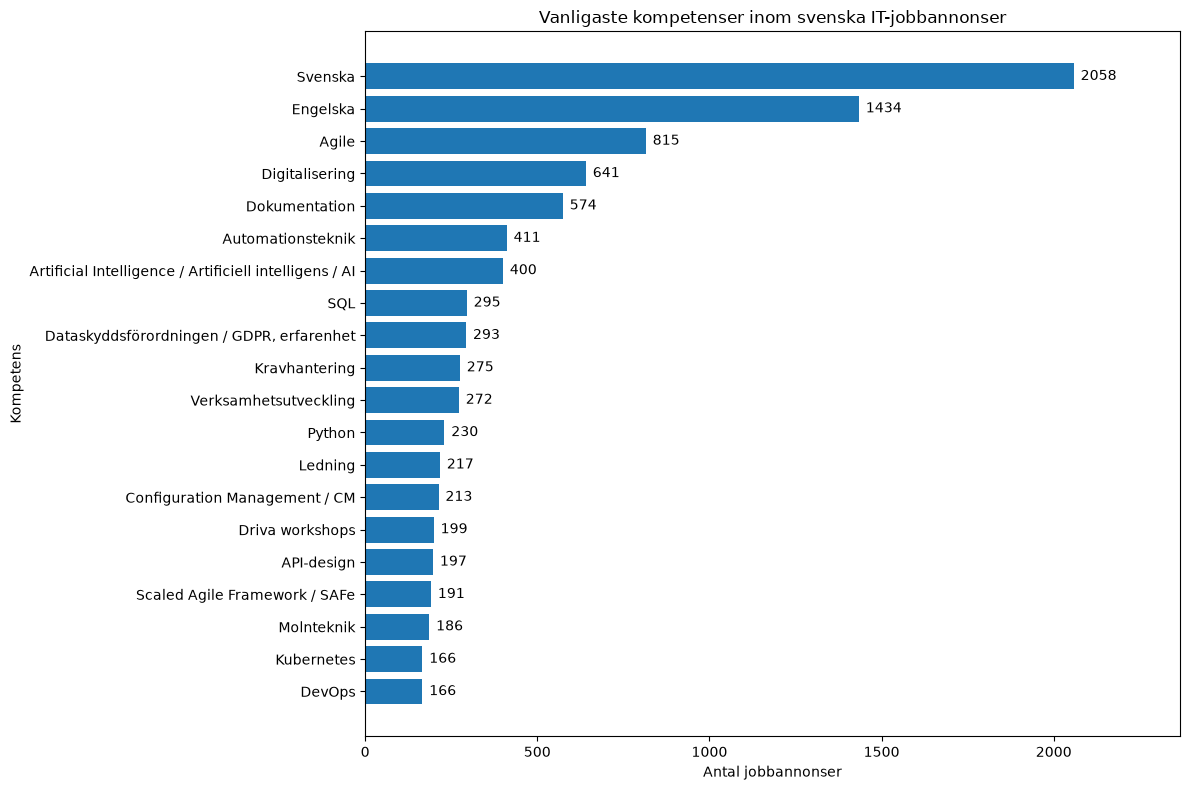

In [ ]:
# Vanligaste kompetenser inom IT-sektorn
counter = Counter(
    skill
    for skills in df_skills["skills"]
    for skill in skills
)

top_20 = pd.DataFrame(
    counter.most_common(20),
    columns=["skill", "n_ads"]
).sort_values("n_ads", ascending=True)

fig, ax = plt.subplots(figsize=(12, 8))

bars = ax.barh(top_20["skill"], top_20["n_ads"])

ax.bar_label(bars, fmt="%.0f", padding=5)

ax.set_xlim(0, top_20["n_ads"].max() * 1.15)

ax.set_title("Vanligaste kompetenser inom svenska IT-jobbannonser")
ax.set_xlabel("Antal jobbannonser")
ax.set_ylabel("Kompetens")

plt.tight_layout()
plt.show()

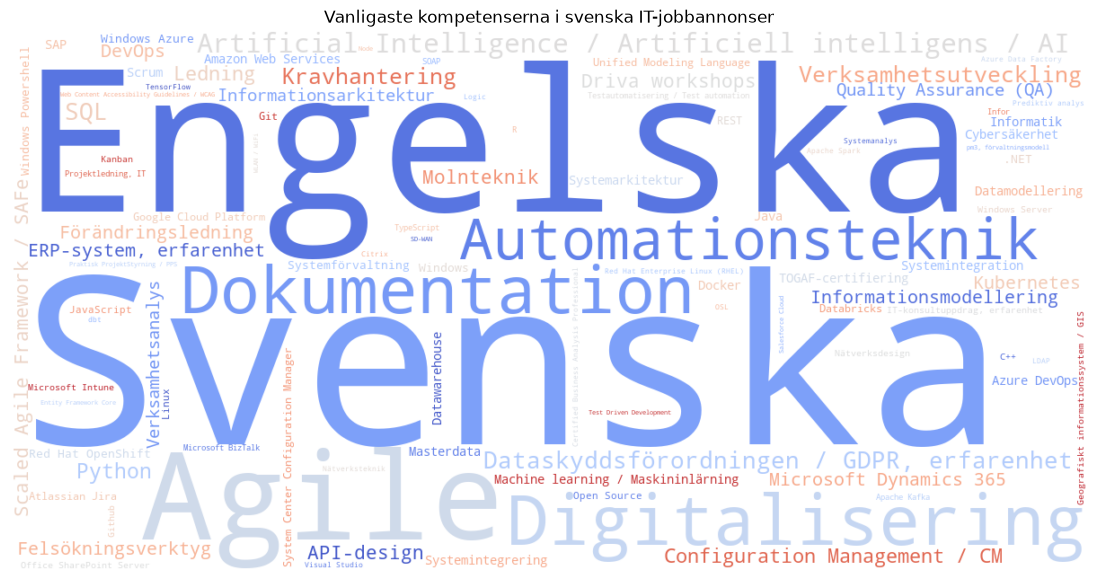

In [ ]:
# Vanligast kompetenser inom IT-sektorn - wordcloud
skill_counts = Counter()

for skills in df_skills["skills"].dropna():
    if isinstance(skills, (set, list, tuple)):
        skill_counts.update(skills)

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    colormap="coolwarm",
    max_words=100,
    collocations=False
).generate_from_frequencies(skill_counts)

plt.figure(figsize=(14, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Vanligaste kompetenserna i svenska IT-jobbannonser")
plt.show()


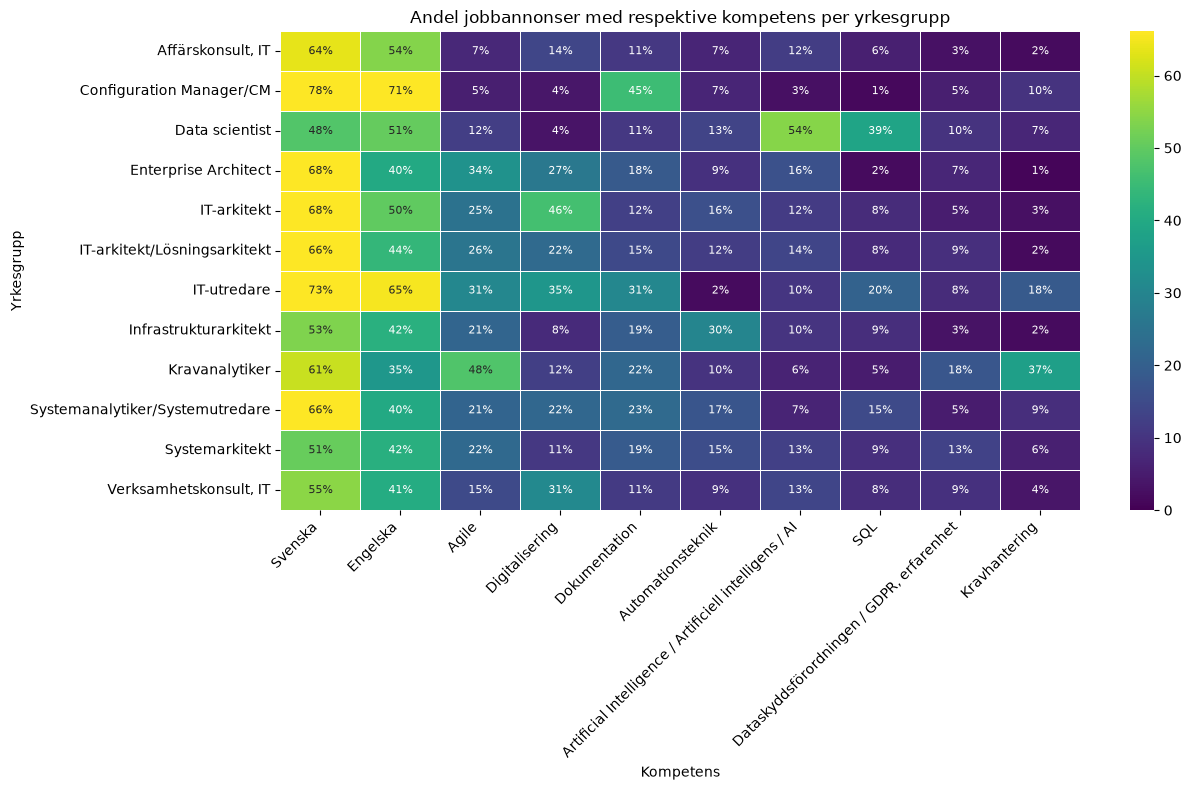

In [ ]:
# Kompetenser enligt yrkesgrupper
# Välj yrkesgrupper med minst 30 annonser
occ_counts = df_skills["occupation"].value_counts()
big_occ = occ_counts[occ_counts >= 30].index

df_occ = (
    df_skills[df_skills["occupation"].isin(big_occ)]
    .copy()
    .reset_index(drop=True)
)


exploded = df_occ.explode("skills").reset_index(drop=True) # En rad per annons och kompetens


exploded = exploded.dropna(subset=["occupation", "skills"]) # Ta bort rader utan kompetens eller yrkesgrupp

# Räkna antal annonser per yrkesgrupp och kompetens
heatmap_data = pd.crosstab(
    exploded["occupation"],
    exploded["skills"]
)

# Välj de 10 vanligaste kompetenserna i det filtrerade urvalet
top_skills_heatmap = (
    exploded["skills"].value_counts().head(10).index
)

heatmap_data = heatmap_data.loc[:, top_skills_heatmap]

# Visa andelen annonser inom varje yrkesgrupp (%)
heatmap_share = heatmap_data.div(
    df_occ.groupby("occupation")["id"].nunique(),
    axis=0
) * 100


plt.figure(figsize=(13, 8))

labels = heatmap_share.map(lambda x: f"{x:.0f}%")

sns.heatmap(
    heatmap_share,
    cmap="viridis",
    vmin=0,
    vmax=heatmap_share.stack().quantile(0.95), # värden över den 95:e percentilen får samma maximala färg, så att variationen bland de lägre värdena blir lättare att se
    annot=labels,
    fmt="",
    annot_kws={"size": 8},
    linewidths=0.5
)

plt.title("Andel jobbannonser med respektive kompetens per yrkesgrupp")
plt.xlabel("Kompetens")
plt.ylabel("Yrkesgrupp")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


### Ändringar i kompetensförfrågan

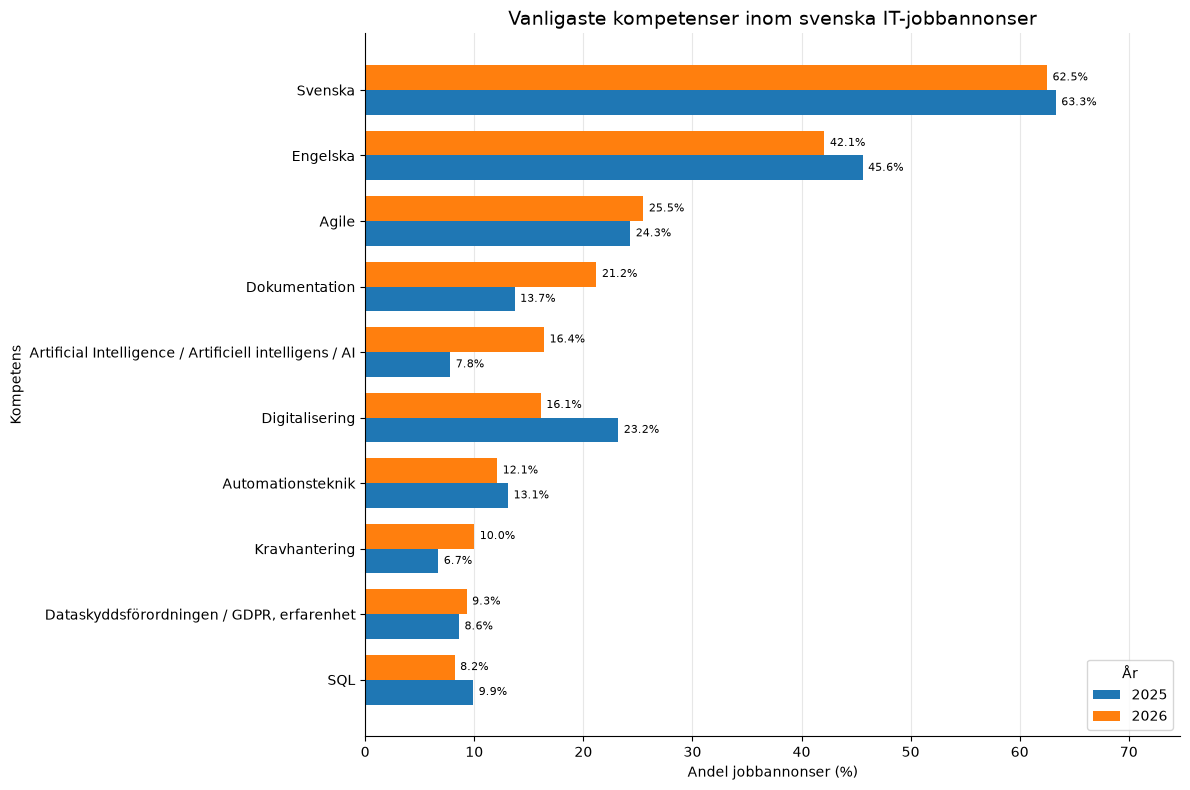

In [ ]:
# Förändring i efterfrågan på kompetenser mellan åren
jan_aug_skills = analysis_df.copy()

# Beräkna andelen annonser per kompetens och år
comparison_ads = share_by(
    jan_aug_skills,
    "year",
    top_skills
).T * 100

comparison_ads.columns = comparison_ads.columns.astype(int) # Om årskolumnerna är strängar, konvertera dem till heltal


comparison_ads = comparison_ads.sort_values(by=2026, ascending=True) # Sortera efter efterfrågan 2026

fig, ax = plt.subplots(figsize=(12, 8))

y = np.arange(len(comparison_ads.index))
height = 0.38

bars_2025 = ax.barh(
    y - height / 2,
    comparison_ads[2025],
    height,
    label="2025"
)

bars_2026 = ax.barh(
    y + height / 2,
    comparison_ads[2026],
    height,
    label="2026"
)


ax.bar_label(bars_2025, fmt="%.1f%%", padding=4, fontsize=8)
ax.bar_label(bars_2026, fmt="%.1f%%", padding=4, fontsize=8)

ax.set_yticks(y)
ax.set_yticklabels(comparison_ads.index)

ax.set_title(
    "Vanligaste kompetenser inom svenska IT-jobbannonser",
    fontsize=14
)
ax.set_xlabel("Andel jobbannonser (%)")
ax.set_ylabel("Kompetens")

ax.legend(title="År")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

ax.set_xlim(0, comparison_ads.max().max() * 1.18) # Ge utrymme för procentetiketterna

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


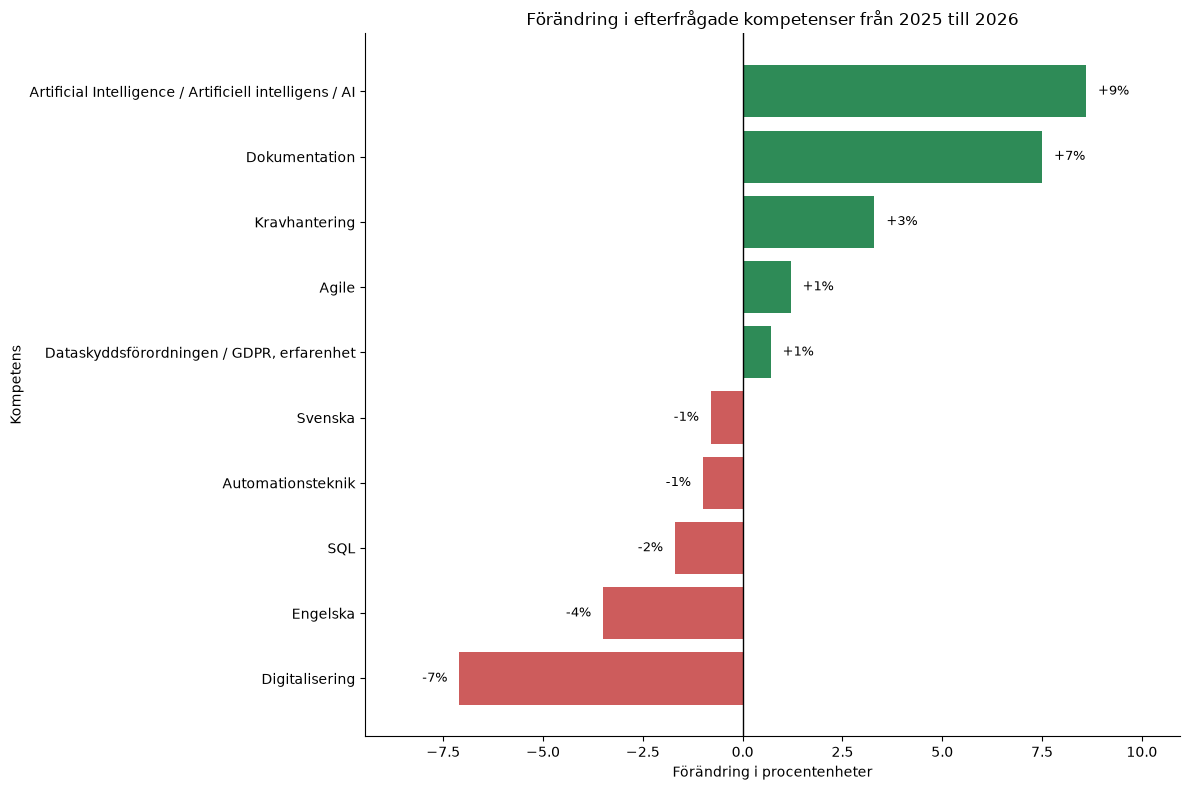

In [ ]:
# Förändring i topp efterfrågade kompetenser mellan 2025 och 2026
comparison = share_by(jan_aug_skills, "year", top_skills).T # Beräkna andelen annonser per kompetens och år

# Förändring mellan 2026 och 2025 i procentenheter
change = (comparison[2026] - comparison[2025]) * 100
change = change.sort_values()

colors = ["indianred" if x < 0 else "seagreen" for x in change] # Rött för negativa värden, grönt för positiva

fig, ax = plt.subplots(figsize=(12, 8))

bars = ax.barh(
    change.index,
    change.values,
    color=colors
)

ax.axvline(0, color="black", linewidth=1) # Behåll nollinjen

# Lägg till procenttal utan decimaler vid varje stapel
for bar, value in zip(bars, change.values):
    offset = 0.3 if value >= 0 else -0.3

    ax.text(
        value + offset,
        bar.get_y() + bar.get_height() / 2,
        f"{value:+.0f}%",
        va="center",
        ha="left" if value >= 0 else "right",
        fontsize=9
    )


ax.set_title("Förändring i efterfrågade kompetenser från 2025 till 2026")
ax.set_xlabel("Förändring i procentenheter")
ax.set_ylabel("Kompetens")

ax.margins(x=0.15) # Ge utrymme för etiketterna utanför staplarna
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

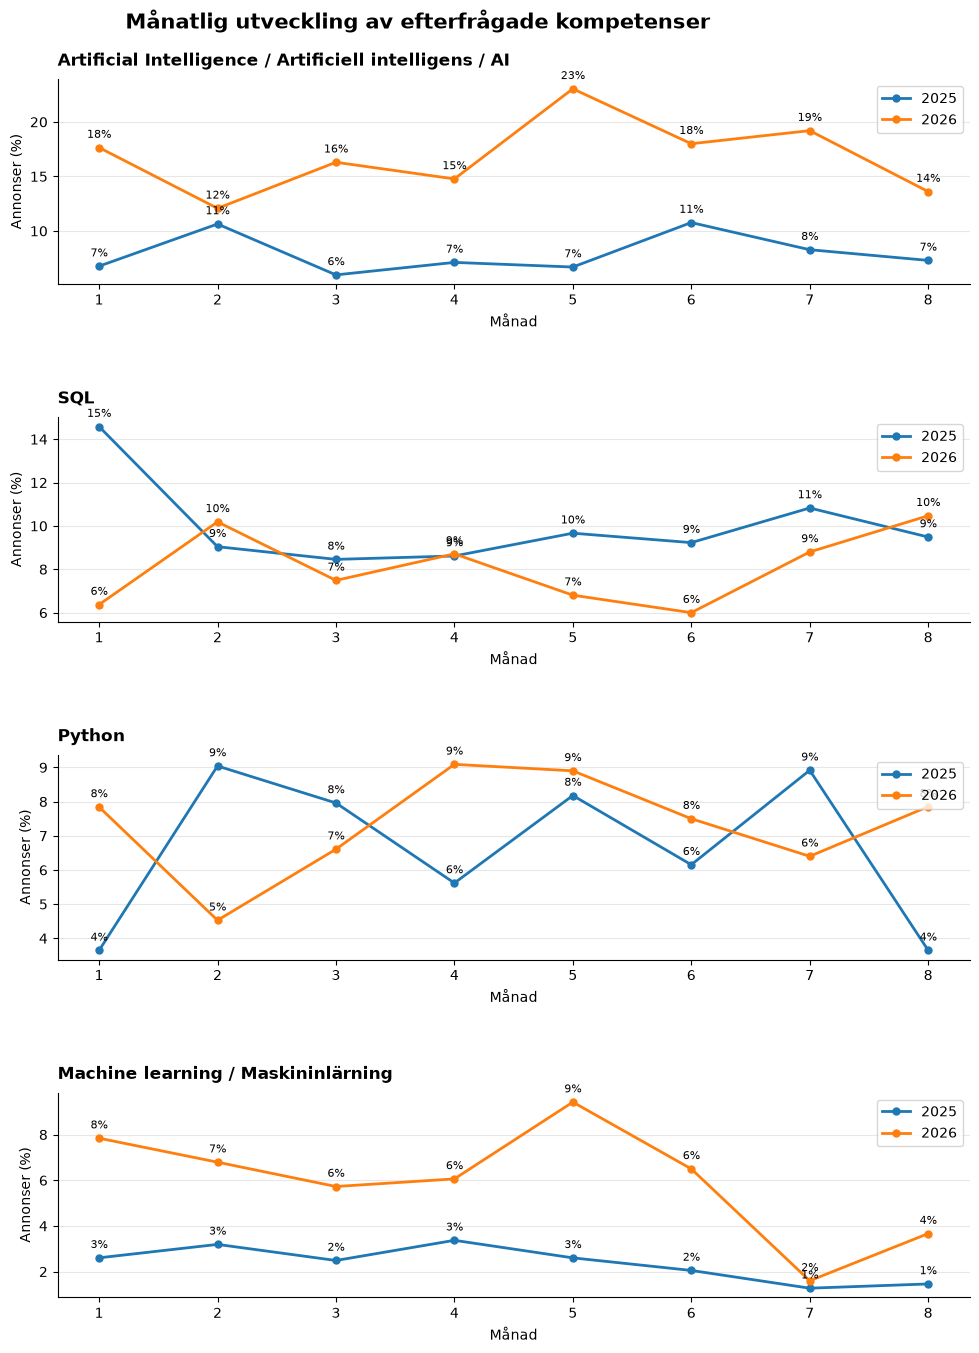

In [ ]:
# Månatlig utveckling av utvalda kompetenser
selected_skills = [
    "Artificial Intelligence / Artificiell intelligens / AI",
    "SQL",
    "Python",
    "Machine learning / Maskininlärning",
]

monthly = jan_aug_skills.copy()

# Totalt antal annonser per år och månad
monthly_totals = (
    monthly.groupby(["year", "month"])
    .size()
    .rename("total_ads")
)

exploded = monthly.explode("skills") # En rad per annons och kompetens

# Antal annonser som innehåller respektive kompetens
monthly_counts = (
    exploded[exploded["skills"].isin(selected_skills)]
    .groupby(["year", "month", "skills"])["id"]
    .nunique()
    .rename("skill_ads")
)

monthly_stats = monthly_counts.reset_index()

monthly_stats["total_ads"] = [
    monthly_totals.loc[(y, m)]
    for y, m in zip(monthly_stats["year"], monthly_stats["month"])
]

monthly_stats["share"] = (
    monthly_stats["skill_ads"] / monthly_stats["total_ads"] * 100
)

# Ett diagram per kompetens
fig, axes = plt.subplots(
    len(selected_skills),
    1,
    figsize=(12, 14),
    sharex=True
)

for ax, skill in zip(axes, selected_skills):
    data = monthly_stats[monthly_stats["skills"] == skill]

    for year in [2025, 2026]:
        year_data = data[data["year"] == year].sort_values("month")

        ax.plot(
            year_data["month"],
            year_data["share"],
            marker="o",
            markersize=5,
            linewidth=2,
            label=str(year)
        )

        # Lägg till procenttal vid varje punkt
        for x, y in zip(year_data["month"], year_data["share"]):
            ax.annotate(
                f"{y:.0f}%",
                (x, y),
                textcoords="offset points",
                xytext=(0, 7),
                ha="center",
                fontsize=8
            )

    ax.set_title(skill, loc="left", fontsize=12, fontweight="bold", pad=10)
    ax.set_ylabel("Annonser (%)", fontsize=10)
    ax.set_xticks(range(1, 9))
    ax.tick_params(axis="x", labelbottom=True)
    ax.set_xlabel("Månad", fontsize=10)
    ax.grid(axis="y", alpha=0.3)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(loc="upper right")

for ax in axes:
    ax.set_xlabel("Månad", fontsize=10)

# Huvudrubrik med extra utrymme
fig.suptitle(
    "Månatlig utveckling av efterfrågade kompetenser",
    fontsize=15,
    fontweight="bold",
    y=0.99
)

# Större avstånd mellan graferna och plats för rubrik/legend
fig.subplots_adjust(
    hspace=0.65,
    top=0.94,
    bottom=0.07,
    left=0.20,
    right=0.96
)

plt.show()

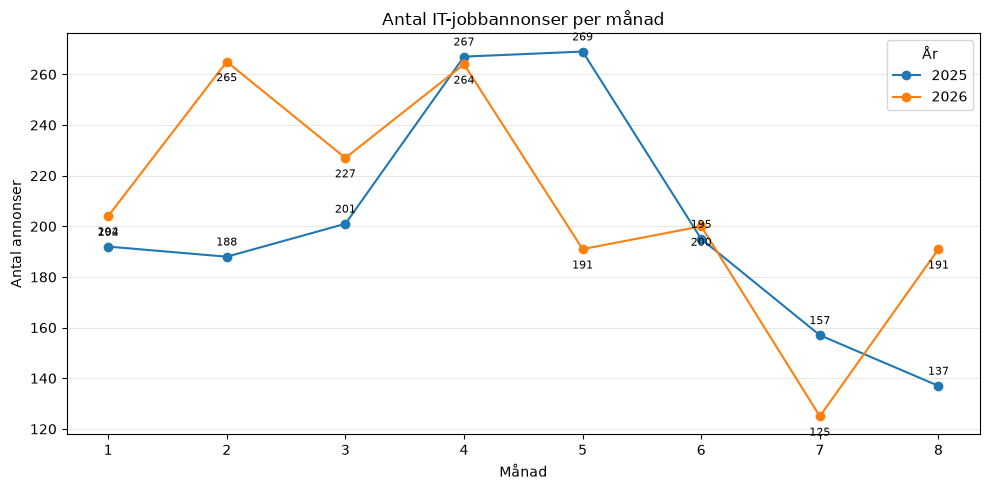

In [ ]:
# Antal jobbannonser per månad och år
monthly_ads = (
    jan_aug_skills.groupby(["year", "month"])
    .size()
    .unstack("year", fill_value=0)
)

ax = monthly_ads.plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

ax.set(
    title="Antal IT-jobbannonser per månad",
    xlabel="Månad",
    ylabel="Antal annonser",
    xticks=range(1, 9)
)

ax.legend(title="År")

# Lägg till siffror vid varje datapunkt
for year in monthly_ads.columns:
    for month, value in monthly_ads[year].items():
        ax.annotate(
            f"{value:.0f}",
            (month, value),
            textcoords="offset points",
            xytext = (0, 8) if year == 2025 else (0, -14),
            ha="center",
            fontsize=8
        )

ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

#### Regionala skillnader i efterfrågade kompetenser

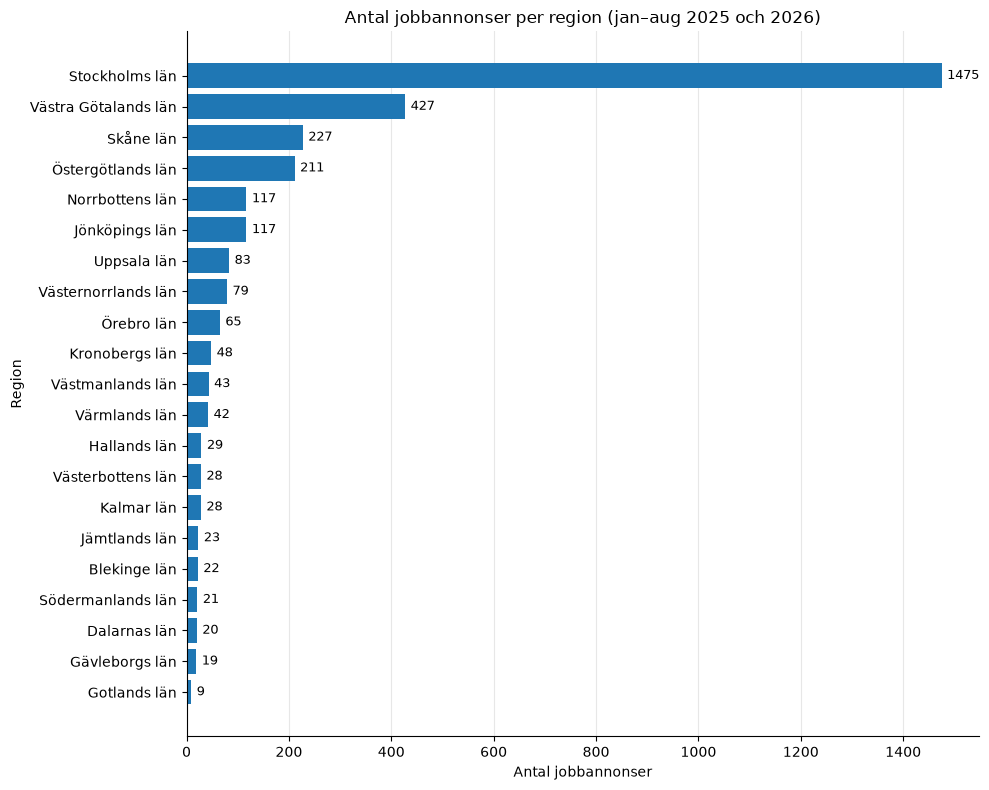

In [51]:
# Antal annonser per region
region_counts = analysis_df["region"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(10, 8))

bars = ax.barh(
    region_counts.index,
    region_counts.values
)

# Visa antal annonser vid slutet av varje stapel
ax.bar_label(bars, fmt="%.0f", padding=4, fontsize=9)

ax.set_title(
    "Antal jobbannonser per region (jan–aug 2025 och 2026)"
)
ax.set_xlabel("Antal jobbannonser")
ax.set_ylabel("Region")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

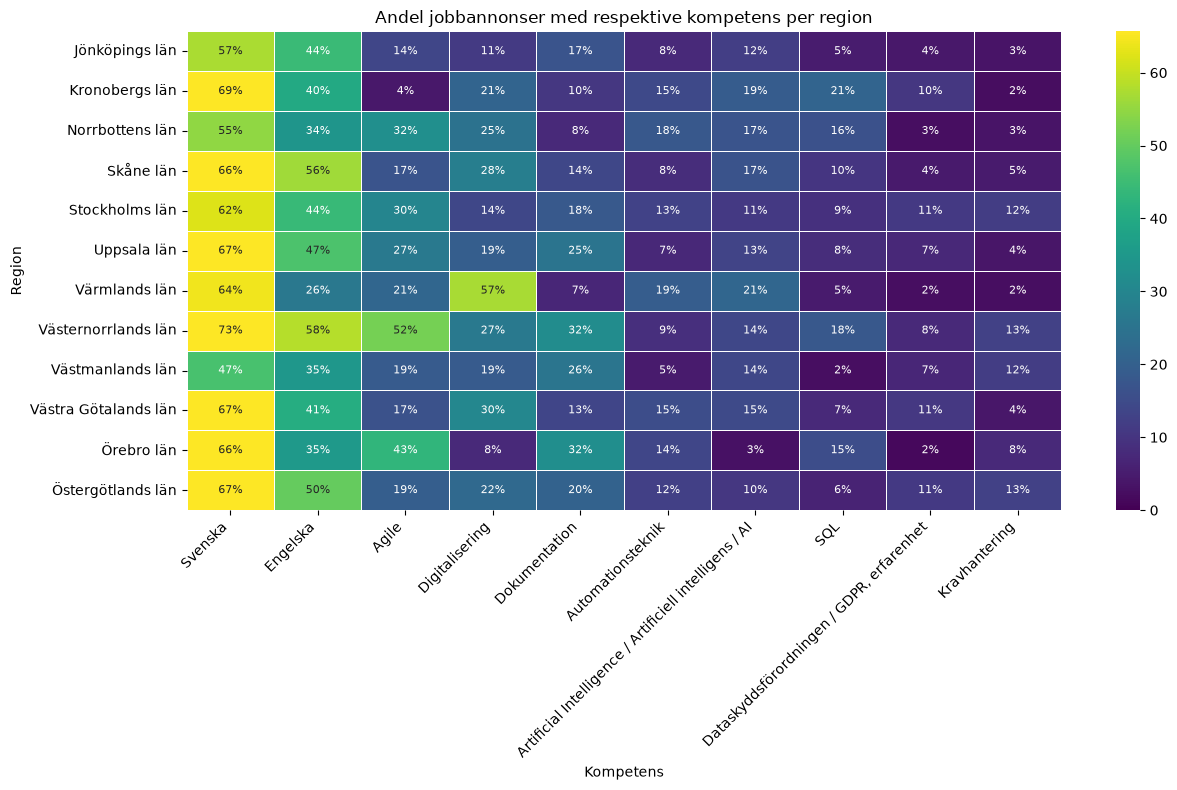

In [ ]:
# Kompetenser enligt region

# Välj regioner med minst 30 annonser
region_counts = df_skills["region"].value_counts()
big_regions = region_counts[region_counts >= 30].index

df_region = (
    df_skills[df_skills["region"].isin(big_regions)]
    .copy()
    .reset_index(drop=True)
)

exploded = df_region.explode("skills").reset_index(drop=True) # En rad per annons och kompetens

exploded = exploded.dropna(subset=["region", "skills"]) # Ta bort rader utan region eller kompetens

# Räkna antal annonser per region och kompetens
heatmap_data = pd.crosstab(
    exploded["region"],
    exploded["skills"]
)

# Välj de 10 vanligaste kompetenserna i det filtrerade urvalet
top_skills_heatmap = (
    exploded["skills"].value_counts().head(10).index
)

heatmap_data = heatmap_data.loc[:, top_skills_heatmap]

# Beräkna andelen annonser inom varje region (%)
heatmap_share = heatmap_data.div(
    df_region.groupby("region")["id"].nunique(),
    axis=0
) * 100

# Rita heatmap
plt.figure(figsize=(13, 8))

labels = heatmap_share.map(lambda x: f"{x:.0f}%")

sns.heatmap(
    heatmap_share,
    cmap="viridis",
    vmin=0,
    vmax=heatmap_share.stack().quantile(0.95),
    annot=labels,
    fmt="",
    annot_kws={"size": 8},
    linewidths=0.5
)

plt.title("Andel jobbannonser med respektive kompetens per region")
plt.xlabel("Kompetens")
plt.ylabel("Region")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()